# Las Vegas vs Phoenix Climate Similarity Analysis

**Purpose:** Determine objectively whether Las Vegas and Phoenix can be treated as a similar-climate city pair for cross-city LSTM generalization.

The notebook:
- loads the four supplied CSV files
- validates schemas, timestamps, coverage, duplicates, and missingness
- identifies common weather variables
- compares descriptive statistics and monthly/seasonal climatology
- calculates standardized mean differences
- calculates Wasserstein and Kolmogorov-Smirnov distribution distances
- compares weather correlation structures
- calculates a standardized multivariate climate distance
- converts the distances into transparent similarity scores
- produces publication/viva-ready plots and tables
- generates Markdown and HTML reports with the actual computed findings

**Important:** No similarity result is hard-coded. All conclusions are generated from the files when this notebook is run.


## 1. Configuration

The paths below are the exact Windows paths supplied for the project. If the files are moved, change only this cell.

In [1]:
from pathlib import Path
import sys, json, math, warnings
warnings.filterwarnings("ignore")

BASE = Path.cwd().parent

FILES = {
    "Las Vegas": {
        "energy": BASE / "data" / "las_vegas_hourly_energy.csv",
        "weather": BASE / "data" / "las_vegas_hourly_weather_2016_2023.csv",
    },
    "Phoenix": {
        "energy": BASE / "data" / "phoenix_hourly_energy.csv",
        "weather": BASE / "data" / "phoenix_hourly_weather_2016_2023.csv",
    },
}

OUTPUT = BASE / "climate_similarity_analysis"
TABLE_DIR = OUTPUT / "tables"
PLOT_DIR = OUTPUT / "plots"
REPORT_DIR = OUTPUT / "report"

for p in [OUTPUT, TABLE_DIR, PLOT_DIR, REPORT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

for city, files in FILES.items():
    for kind, path in files.items():
        print(f"{city:12s} {kind:7s}: {path} | exists={path.exists()}")

print("\nOutput folder:", OUTPUT)


Las Vegas    energy : D:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_energy.csv | exists=True
Las Vegas    weather: D:\Downloads\BTP\model_training\lstm_training_3\las_vegas_hourly_weather_2016_2023.csv | exists=True
Phoenix      energy : D:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_energy.csv | exists=True
Phoenix      weather: D:\Downloads\BTP\model_training\lstm_training_3\phoenix_hourly_weather_2016_2023.csv | exists=True

Output folder: D:\Downloads\BTP\model_training\lstm_training_3\climate_similarity_analysis


## 2. Package check and imports

In [2]:
required = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "seaborn": "seaborn",
}

missing = []
for module, package in required.items():
    try:
        __import__(module)
    except ImportError:
        missing.append(package)

if missing:
    print("Missing packages:", missing)
    print("Run in Anaconda Prompt/Jupyter terminal:")
    print("pip install " + " ".join(sorted(set(missing))))
else:
    print("All required packages are available.")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import wasserstein_distance, ks_2samp
from scipy.spatial.distance import euclidean
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import pairwise_distances

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")


All required packages are available.


## 3. Load and inspect all four files

The analysis deliberately keeps **weather** as the basis of climate similarity. Energy is inspected separately and is not used to define the climate-pair score, preventing the target variable from influencing the city-pair selection.

In [3]:
def read_csv_robust(path):
    return pd.read_csv(path, low_memory=False)

data = {}
for city, files in FILES.items():
    data[city] = {}
    for kind, path in files.items():
        df = read_csv_robust(path)
        data[city][kind] = df
        print(f"\n{'='*80}\n{city} - {kind.upper()}")
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))
        display(df.head(3))



Las Vegas - ENERGY
Shape: (70128, 2)
Columns: ['timestamp', 'hourly_load_mw']


,timestamp,hourly_load_mw
0,2016-01-01 00:00:00,"2,792.3110"
1,2016-01-01 01:00:00,"2,975.4558"
2,2016-01-01 02:00:00,"3,270.8487"



Las Vegas - WEATHER
Shape: (70080, 25)
Columns: ['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'timestamp']


,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,opaque_sky_cover_tenths,temperature_c,dew_point_c,relative_humidity_percent,station_pressure_kpa,wind_direction_deg,wind_speed_ms,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm,timestamp
0,2016-01-01,1,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,-1.1000,-8.9000,56.0000,94.8000,200.0000,3.9000,24.1000,"10,395.0000",0,999999999,5.0000,0.1070,0.0000,88.0000,0.0000,2016-01-01 00:00:00
1,2016-01-01,2,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,-0.6000,-8.9000,54.0000,94.9000,250.0000,3.4000,24.1000,"10,395.0000",0,999999999,5.0000,0.1070,0.0000,88.0000,0.0000,2016-01-01 01:00:00
2,2016-01-01,3,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,-1.7000,-8.9000,58.0000,94.9000,250.0000,2.3000,24.1000,"10,395.0000",0,999999999,5.0000,0.1070,0.0000,88.0000,0.0000,2016-01-01 02:00:00



Phoenix - ENERGY
Shape: (70128, 2)
Columns: ['timestamp', 'hourly_load_mw']


,timestamp,hourly_load_mw
0,2016-01-01 00:00:00,"4,501.2727"
1,2016-01-01 01:00:00,"4,981.1647"
2,2016-01-01 02:00:00,"5,373.8907"



Phoenix - WEATHER
Shape: (70080, 25)
Columns: ['date', 'hour', 'extraterrestrial_horizontal_radiation_wh_m2', 'extraterrestrial_direct_normal_radiation_wh_m2', 'global_horizontal_radiation_wh_m2', 'direct_normal_radiation_wh_m2', 'diffuse_horizontal_radiation_wh_m2', 'total_sky_cover_tenths', 'opaque_sky_cover_tenths', 'temperature_c', 'dew_point_c', 'relative_humidity_percent', 'station_pressure_kpa', 'wind_direction_deg', 'wind_speed_ms', 'horizontal_visibility_km', 'ceiling_height_m', 'observation_indicator', 'present_weather', 'precipitable_water_mm', 'broadband_aerosol_optical_depth', 'snow_depth_cm', 'days_since_last_snowfall', 'hourly_precipitation_cm', 'timestamp']


,date,hour,extraterrestrial_horizontal_radiation_wh_m2,extraterrestrial_direct_normal_radiation_wh_m2,global_horizontal_radiation_wh_m2,direct_normal_radiation_wh_m2,diffuse_horizontal_radiation_wh_m2,total_sky_cover_tenths,opaque_sky_cover_tenths,temperature_c,dew_point_c,relative_humidity_percent,station_pressure_kpa,wind_direction_deg,wind_speed_ms,horizontal_visibility_km,ceiling_height_m,observation_indicator,present_weather,precipitable_water_mm,broadband_aerosol_optical_depth,snow_depth_cm,days_since_last_snowfall,hourly_precipitation_cm,timestamp
0,2016-01-01,1,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,7.2000,-1.1000,56.0000,98.3000,100.0000,2.6000,56.3000,"16,764.0000",0,999999999,8.0000,0.1780,0.0000,88.0000,0.0000,2016-01-01 00:00:00
1,2016-01-01,2,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,6.1000,-1.7000,58.0000,98.4000,140.0000,2.1000,56.3000,"16,764.0000",0,999999999,8.0000,0.1780,0.0000,88.0000,0.0000,2016-01-01 01:00:00
2,2016-01-01,3,0.0000,0.0000,NaN,NaN,NaN,0.0000,0.0000,5.6000,-1.7000,60.0000,98.4000,100.0000,3.1000,56.3000,"16,764.0000",0,999999999,8.0000,0.1780,0.0000,88.0000,0.0000,2016-01-01 02:00:00


## 4. Timestamp detection and data-quality audit

In [4]:
TIME_HINTS = [
    "timestamp", "datetime", "date_time", "date", "time", "local_time",
    "utc_time", "start_time", "end_time"
]

def detect_time_column(df):
    candidates = []
    for c in df.columns:
        name = str(c).strip().lower().replace(" ", "_")
        score = sum(h in name for h in TIME_HINTS)
        if score:
            candidates.append((score, c))
    # Prefer columns with strong datetime parsing success
    ranked = []
    for _, c in sorted(candidates, reverse=True):
        parsed = pd.to_datetime(df[c], errors="coerce")
        rate = parsed.notna().mean()
        ranked.append((rate, c))
    if ranked and ranked[0][0] >= 0.5:
        return ranked[0][1]
    return None

audit_rows = []
for city in data:
    for kind in ["weather", "energy"]:
        df = data[city][kind]
        time_col = detect_time_column(df)
        parsed = pd.to_datetime(df[time_col], errors="coerce") if time_col else pd.Series(pd.NaT, index=df.index)
        audit_rows.append({
            "city": city,
            "dataset": kind,
            "rows": len(df),
            "columns": df.shape[1],
            "timestamp_column": time_col,
            "valid_timestamp_pct": parsed.notna().mean() * 100,
            "start": parsed.min(),
            "end": parsed.max(),
            "duplicate_rows": int(df.duplicated().sum()),
            "missing_cells": int(df.isna().sum().sum()),
            "missing_cell_pct": df.isna().mean().mean() * 100,
        })

audit = pd.DataFrame(audit_rows)
display(audit)
audit.to_csv(TABLE_DIR / "data_quality_audit.csv", index=False)


,city,dataset,rows,columns,timestamp_column,valid_timestamp_pct,start,end,duplicate_rows,missing_cells,missing_cell_pct
0,Las Vegas,weather,70080,25,timestamp,100.0000,2016-01-01,2023-12-31 23:00:00,0,210240,12.0000
1,Las Vegas,energy,70128,2,timestamp,100.0000,2016-01-01,2023-12-31 23:00:00,0,0,0.0000
2,Phoenix,weather,70080,25,timestamp,100.0000,2016-01-01,2023-12-31 23:00:00,0,210240,12.0000
3,Phoenix,energy,70128,2,timestamp,100.0000,2016-01-01,2023-12-31 23:00:00,0,0,0.0000


## 5. Normalize weather data

The next cell uses aliases to find common meteorological variables even if the CSV column names differ slightly. The original columns are preserved.

If a variable cannot be detected automatically, the notebook reports it instead of silently guessing.

In [5]:
ALIASES = {
    "temperature": [
        "temperature", "temp", "air_temperature", "dry_bulb_temperature",
        "drybulb", "tmp"
    ],
    "dew_point": [
        "dew_point", "dewpoint", "dew point", "dew_point_temperature", "dewp"
    ],
    "relative_humidity": [
        "relative_humidity", "humidity", "rh", "relative humidity"
    ],
    "pressure": [
        "pressure", "sea_level_pressure", "station_pressure", "atmospheric_pressure",
        "slp", "mslp"
    ],
    "wind_speed": [
        "wind_speed", "windspeed", "wind speed", "ws", "wind"
    ],
    "wind_direction": [
        "wind_direction", "wind_dir", "wind direction", "wd"
    ],
    "visibility": [
        "visibility", "vis"
    ],
    "precipitation": [
        "precipitation", "precip", "precipitation_amount", "rain", "rainfall"
    ],
}

def norm_name(x):
    return "".join(ch for ch in str(x).lower().strip() if ch.isalnum())

def find_alias(df, aliases):
    normalized = {norm_name(c): c for c in df.columns}
    for alias in aliases:
        a = norm_name(alias)
        if a in normalized:
            return normalized[a]
    # softer substring matching
    for c in df.columns:
        nc = norm_name(c)
        for alias in aliases:
            a = norm_name(alias)
            if len(a) >= 4 and (a in nc or nc in a):
                return c
    return None

weather_info = {}
for city in data:
    df = data[city]["weather"].copy()
    time_col = detect_time_column(df)
    if time_col:
        df["_timestamp"] = pd.to_datetime(df[time_col], errors="coerce")
    else:
        df["_timestamp"] = pd.NaT

    mapping = {feature: find_alias(df, aliases) for feature, aliases in ALIASES.items()}
    weather_info[city] = {"df": df, "time_col": time_col, "mapping": mapping}

    print(f"\n{city}")
    for feature, col in mapping.items():
        print(f"  {feature:20s} -> {col}")

common_features = [
    f for f in ALIASES
    if weather_info["Las Vegas"]["mapping"].get(f) is not None
    and weather_info["Phoenix"]["mapping"].get(f) is not None
]

print("\nCommon detected weather variables:", common_features)

if len(common_features) < 3:
    raise ValueError("Fewer than 3 common weather variables were detected. Inspect the mappings above and add aliases if necessary.")



Las Vegas
  temperature          -> temperature_c
  dew_point            -> dew_point_c
  relative_humidity    -> relative_humidity_percent
  pressure             -> station_pressure_kpa
  wind_speed           -> wind_direction_deg
  wind_direction       -> wind_direction_deg
  visibility           -> horizontal_visibility_km
  precipitation        -> precipitable_water_mm

Phoenix
  temperature          -> temperature_c
  dew_point            -> dew_point_c
  relative_humidity    -> relative_humidity_percent
  pressure             -> station_pressure_kpa
  wind_speed           -> wind_direction_deg
  wind_direction       -> wind_direction_deg
  visibility           -> horizontal_visibility_km
  precipitation        -> precipitable_water_mm

Common detected weather variables: ['temperature', 'dew_point', 'relative_humidity', 'pressure', 'wind_speed', 'wind_direction', 'visibility', 'precipitation']


## 6. Build aligned 2016–2023 weather tables

In [6]:
weather = {}

for city in data:
    info = weather_info[city]
    df = info["df"].copy()
    out = pd.DataFrame({"timestamp": df["_timestamp"]})

    for feature in common_features:
        out[feature] = pd.to_numeric(df[info["mapping"][feature]], errors="coerce")

    out = out.dropna(subset=["timestamp"]).sort_values("timestamp")
    out = out.drop_duplicates(subset=["timestamp"], keep="first")
    out = out.set_index("timestamp")

    # Restrict to requested analysis period
    out = out.loc[(out.index >= "2016-01-01") & (out.index < "2024-01-01")]
    weather[city] = out

    print(f"{city}: {out.shape}, {out.index.min()} -> {out.index.max()}")

# Common timestamp intersection is useful for a controlled comparison.
common_start = max(weather[c].index.min() for c in weather)
common_end = min(weather[c].index.max() for c in weather)
print("\nCommon date window:", common_start, "to", common_end)

aligned = {}
for city in weather:
    aligned[city] = weather[city].loc[common_start:common_end].copy()

coverage = pd.DataFrame({
    city: {
        "rows": len(df),
        "valid_rows_pct": df[common_features].notna().all(axis=1).mean() * 100,
        "start": df.index.min(),
        "end": df.index.max(),
        "unique_timestamps": df.index.nunique()
    } for city, df in aligned.items()
}).T
display(coverage)
coverage.to_csv(TABLE_DIR / "weather_coverage.csv")


Las Vegas: (70080, 8), 2016-01-01 00:00:00 -> 2023-12-31 23:00:00
Phoenix: (70080, 8), 2016-01-01 00:00:00 -> 2023-12-31 23:00:00

Common date window: 2016-01-01 00:00:00 to 2023-12-31 23:00:00


,rows,valid_rows_pct,start,end,unique_timestamps
Las Vegas,70080,100.0000,2016-01-01 00:00:00,2023-12-31 23:00:00,70080
Phoenix,70080,100.0000,2016-01-01 00:00:00,2023-12-31 23:00:00,70080


## 7. Missing values and duplicate timestamps after normalization

In [7]:
quality_rows = []
for city, df in aligned.items():
    for feature in common_features:
        quality_rows.append({
            "city": city,
            "feature": feature,
            "missing": int(df[feature].isna().sum()),
            "missing_pct": df[feature].isna().mean() * 100,
            "unique": df[feature].nunique(dropna=True),
        })

weather_quality = pd.DataFrame(quality_rows)
display(weather_quality)
weather_quality.to_csv(TABLE_DIR / "weather_quality.csv", index=False)


,city,feature,missing,missing_pct,unique
0,Las Vegas,temperature,0,0.0000,116
1,Las Vegas,dew_point,0,0.0000,108
2,Las Vegas,relative_humidity,0,0.0000,95
3,Las Vegas,pressure,0,0.0000,44
4,Las Vegas,wind_speed,0,0.0000,38
5,Las Vegas,wind_direction,0,0.0000,38
6,Las Vegas,visibility,0,0.0000,34
7,Las Vegas,precipitation,0,0.0000,49
8,Phoenix,temperature,0,0.0000,108
9,Phoenix,dew_point,0,0.0000,103


## 8. Descriptive climate statistics

These statistics are calculated from the common weather variables and the common date window.

In [8]:
stats_list = []
for city, df in aligned.items():
    desc = df[common_features].describe(percentiles=[.25, .50, .75]).T
    desc["city"] = city
    desc["feature"] = desc.index
    stats_list.append(desc.reset_index(drop=True))

descriptive = pd.concat(stats_list, ignore_index=True)
cols = ["city", "feature", "count", "mean", "std", "min", "25%", "50%", "75%", "max"]
descriptive = descriptive[cols]

display(descriptive)
descriptive.to_csv(TABLE_DIR / "descriptive_statistics.csv", index=False)


,city,feature,count,mean,std,min,25%,50%,75%,max
0,Las Vegas,temperature,"70,080.0000",19.8490,10.6204,-11.7000,11.1000,19.4000,28.3000,46.7000
1,Las Vegas,dew_point,"70,080.0000",-0.5095,7.2672,-26.7000,-5.6000,-1.1000,3.9000,23.9000
2,Las Vegas,relative_humidity,"70,080.0000",31.1109,19.4276,2.0000,16.0000,26.0000,41.0000,100.0000
3,Las Vegas,pressure,"70,080.0000",93.7795,0.5626,91.6000,93.4000,93.7000,94.1000,96.7000
4,Las Vegas,wind_speed,"70,080.0000",197.2048,94.6231,0.0000,140.0000,210.0000,260.0000,360.0000
5,Las Vegas,wind_direction,"70,080.0000",197.2048,94.6231,0.0000,140.0000,210.0000,260.0000,360.0000
6,Las Vegas,visibility,"70,080.0000",62.9209,41.2217,0.0000,24.1000,56.3000,120.7000,120.7000
7,Las Vegas,precipitation,"70,080.0000",11.5588,6.5741,1.0000,7.0000,10.0000,14.0000,49.0000
8,Phoenix,temperature,"70,080.0000",23.8525,9.7716,-2.8000,16.1000,23.9000,31.7000,50.0000
9,Phoenix,dew_point,"70,080.0000",5.2829,7.5813,-21.1000,0.0000,4.4000,10.6000,24.4000


## 9. Variable-level similarity

### Metrics

**Standardized Mean Difference (SMD)**  
Measures the difference in means relative to pooled variability.

\[
SMD = \frac{|\mu_{LV}-\mu_{PHX}|}{\sqrt{(\sigma_{LV}^2+\sigma_{PHX}^2)/2}}
\]

Smaller is more similar.

**Wasserstein distance**  
Measures the minimum amount of probability mass that must be moved to transform one empirical distribution into the other. Smaller is more similar.

**KS statistic**  
Measures the maximum difference between the two empirical cumulative distributions. Smaller is more similar.

Because variables have different physical units, Wasserstein distances are additionally normalized by a pooled standard deviation before contributing to the overall score.

In [9]:
comparison_rows = []

for feature in common_features:
    lv = aligned["Las Vegas"][feature].dropna().values
    phx = aligned["Phoenix"][feature].dropna().values

    lv_mean, phx_mean = np.mean(lv), np.mean(phx)
    lv_std, phx_std = np.std(lv, ddof=1), np.std(phx, ddof=1)
    pooled_std = np.sqrt((lv_std**2 + phx_std**2) / 2)

    smd = abs(lv_mean - phx_mean) / pooled_std if pooled_std > 0 else np.nan
    wd = wasserstein_distance(lv, phx)
    ks = ks_2samp(lv, phx)

    # Unitless normalized Wasserstein distance
    norm_wd = wd / pooled_std if pooled_std > 0 else np.nan

    comparison_rows.append({
        "feature": feature,
        "LV_mean": lv_mean,
        "Phoenix_mean": phx_mean,
        "LV_std": lv_std,
        "Phoenix_std": phx_std,
        "standardized_mean_difference": smd,
        "wasserstein_distance": wd,
        "normalized_wasserstein": norm_wd,
        "KS_statistic": ks.statistic,
        "KS_p_value": ks.pvalue,
        "LV_n": len(lv),
        "Phoenix_n": len(phx),
    })

variable_similarity = pd.DataFrame(comparison_rows)

# A transparent distribution similarity score.
# 100 = identical; 0 approaches extremely dissimilar.
# SMD and normalized Wasserstein are both unitless.
variable_similarity["SMD_similarity"] = 100 * np.exp(-variable_similarity["standardized_mean_difference"])
variable_similarity["Wasserstein_similarity"] = 100 * np.exp(-variable_similarity["normalized_wasserstein"])
variable_similarity["KS_similarity"] = 100 * (1 - variable_similarity["KS_statistic"])

variable_similarity["variable_similarity_score"] = (
    variable_similarity["SMD_similarity"]
    + variable_similarity["Wasserstein_similarity"]
    + variable_similarity["KS_similarity"]
) / 3

display(variable_similarity.sort_values("variable_similarity_score", ascending=False))
variable_similarity.to_csv(TABLE_DIR / "variable_similarity.csv", index=False)


,feature,LV_mean,Phoenix_mean,LV_std,Phoenix_std,standardized_mean_difference,wasserstein_distance,normalized_wasserstein,KS_statistic,KS_p_value,LV_n,Phoenix_n,SMD_similarity,Wasserstein_similarity,KS_similarity,variable_similarity_score
2,relative_humidity,31.1109,35.8288,19.4276,20.3586,0.2371,4.7229,0.2373,0.1153,0.0000,70080,70080,78.8914,78.8717,88.4660,82.0764
7,precipitation,11.5588,13.8824,6.5741,6.9481,0.3435,2.4401,0.3608,0.1621,0.0000,70080,70080,70.9259,69.7142,83.7857,74.8086
0,temperature,19.8490,23.8525,10.6204,9.7716,0.3923,4.0035,0.3923,0.1418,0.0000,70080,70080,67.5490,67.5490,85.8219,73.6400
4,wind_speed,197.2048,152.4351,94.6231,101.8282,0.4555,44.7697,0.4555,0.3028,0.0000,70080,70080,63.4145,63.4145,69.7246,65.5179
5,wind_direction,197.2048,152.4351,94.6231,101.8282,0.4555,44.7697,0.4555,0.3028,0.0000,70080,70080,63.4145,63.4145,69.7246,65.5179
6,visibility,62.9209,58.3567,41.2217,17.1602,0.1446,26.9753,0.8544,0.4170,0.0000,70080,70080,86.5403,42.5547,58.2962,62.4637
1,dew_point,-0.5095,5.2829,7.2672,7.5813,0.7800,5.7923,0.7800,0.3164,0.0000,70080,70080,45.8397,45.8397,68.3604,53.3466
3,pressure,93.7795,97.3872,0.5626,0.4606,7.0171,3.6077,7.0171,0.9996,0.0000,70080,70080,0.0896,0.0896,0.0385,0.0726


## 10. Monthly and seasonal climatology

Climate similarity should not be inferred only from annual averages. We therefore compare the monthly behavior of each common weather variable.

In [10]:
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

monthly_rows = []
seasonal_rows = []

for city, df in aligned.items():
    tmp = df.copy()
    tmp["month"] = tmp.index.month
    tmp["season"] = tmp.index.month.map(season_map)

    monthly = tmp.groupby("month")[common_features].mean()
    monthly["city"] = city
    monthly["month"] = monthly.index
    monthly_rows.append(monthly.reset_index(drop=True))

    seasonal = tmp.groupby("season")[common_features].mean()
    seasonal["city"] = city
    seasonal["season"] = seasonal.index
    seasonal_rows.append(seasonal.reset_index(drop=True))

monthly_means = pd.concat(monthly_rows, ignore_index=True)
seasonal_means = pd.concat(seasonal_rows, ignore_index=True)

display(monthly_means)
display(seasonal_means)

monthly_means.to_csv(TABLE_DIR / "monthly_weather_means.csv", index=False)
seasonal_means.to_csv(TABLE_DIR / "seasonal_weather_means.csv", index=False)


,temperature,dew_point,relative_humidity,pressure,wind_speed,wind_direction,visibility,precipitation,city,month
0,7.5547,-4.2793,47.3402,94.3400,204.4540,204.4540,58.6130,7.6079,Las Vegas,1
1,10.4262,-4.2192,40.0164,94.0744,202.5056,202.5056,60.6959,7.6914,Las Vegas,2
2,14.9189,-3.3864,32.3535,93.7598,202.2631,202.2631,65.6700,8.4293,Las Vegas,3
3,19.4034,-2.5307,26.5314,93.5813,197.9462,197.9462,65.7501,8.9786,Las Vegas,4
4,24.8100,-1.8328,19.9481,93.4060,198.3837,198.3837,68.0741,10.3846,Las Vegas,5
5,30.3919,0.9771,17.1089,93.3655,191.3160,191.3160,68.9002,13.1057,Las Vegas,6
6,32.6135,6.2346,23.0697,93.5062,191.1845,191.1845,65.1522,18.6781,Las Vegas,7
7,31.1103,7.6350,27.8851,93.5784,184.4086,184.4086,63.4355,20.1386,Las Vegas,8
8,26.6357,3.1484,25.4283,93.5811,189.2153,189.2153,61.5250,14.9828,Las Vegas,9
9,20.1095,0.2772,30.1853,93.8831,189.5548,189.5548,62.4947,11.4575,Las Vegas,10


,temperature,dew_point,relative_humidity,pressure,wind_speed,wind_direction,visibility,precipitation,city,season
0,19.7424,0.0032,30.9088,93.8339,195.2312,195.2312,60.8116,11.8325,Las Vegas,Autumn
1,19.7141,-2.5839,26.2749,93.5824,199.5482,199.5482,66.5062,9.2673,Las Vegas,Spring
2,31.3825,4.9921,22.7485,93.4847,188.9442,188.9442,65.7959,17.3531,Las Vegas,Summer
3,8.3049,-4.5312,44.8068,94.2275,205.2491,205.2491,58.4497,7.7015,Las Vegas,Winter
4,24.1960,7.4092,38.5885,97.4061,136.8641,136.8641,59.2095,15.4778,Phoenix,Autumn
5,23.6775,1.4497,27.6792,97.2451,165.0481,165.0481,60.6445,10.2523,Phoenix,Spring
6,34.0102,11.3913,29.3152,97.1025,175.2129,175.2129,61.1843,19.7704,Phoenix,Summer
7,13.3008,0.8071,48.0274,97.8044,132.0020,132.0020,52.2652,9.9612,Phoenix,Winter


## 11. Distribution plots

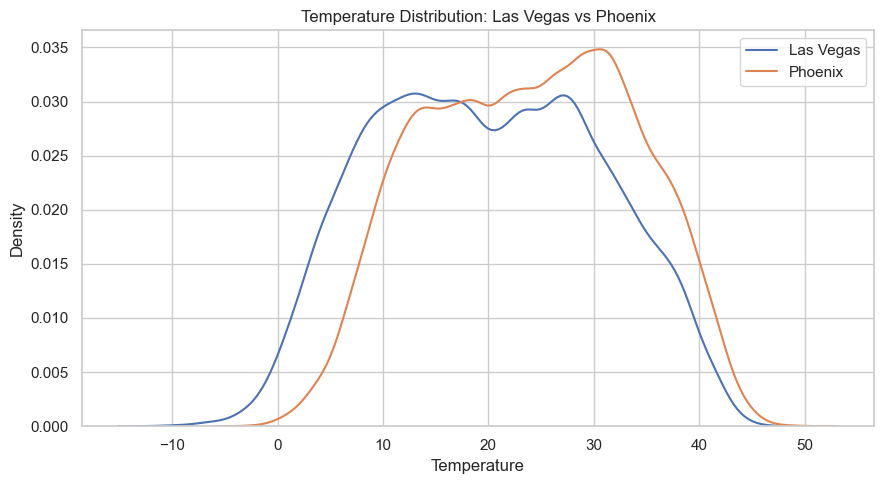

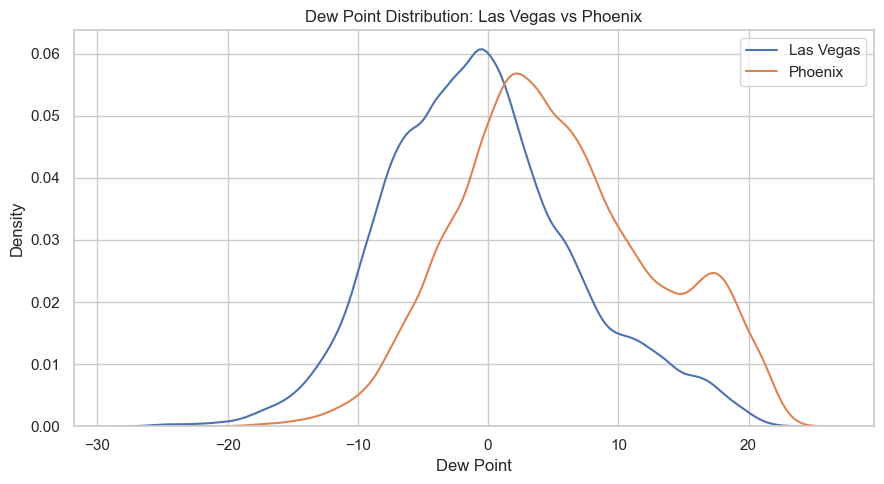

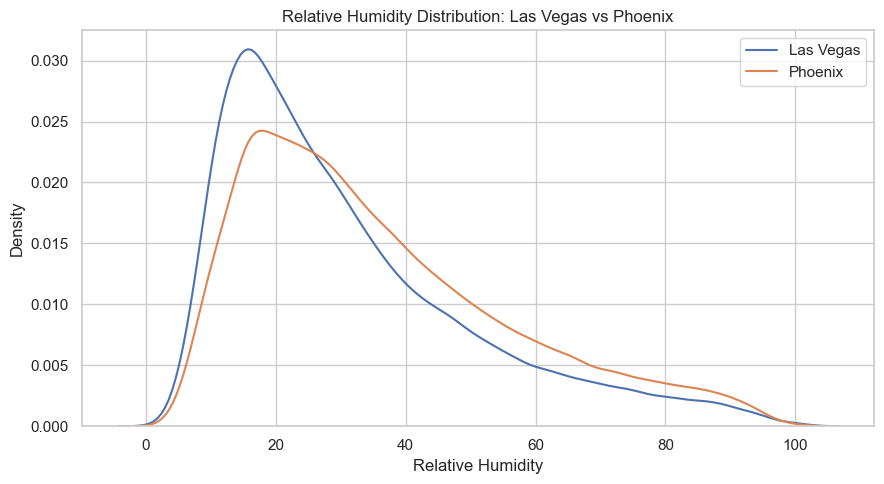

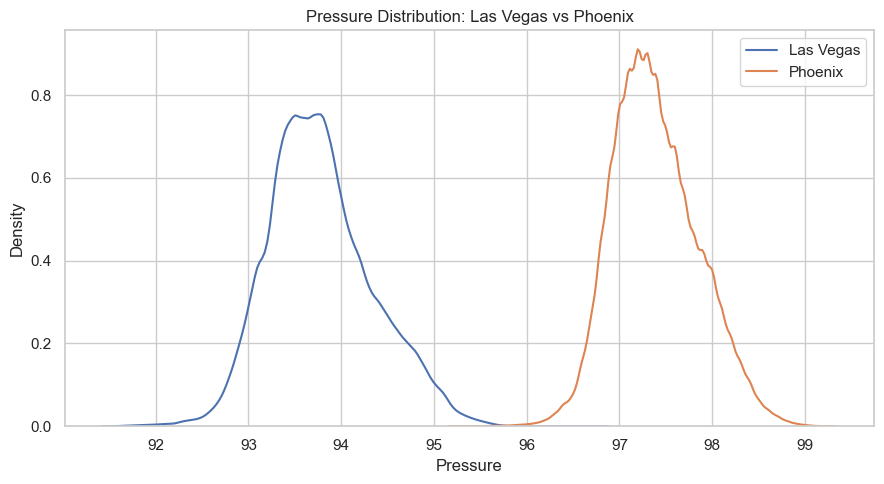

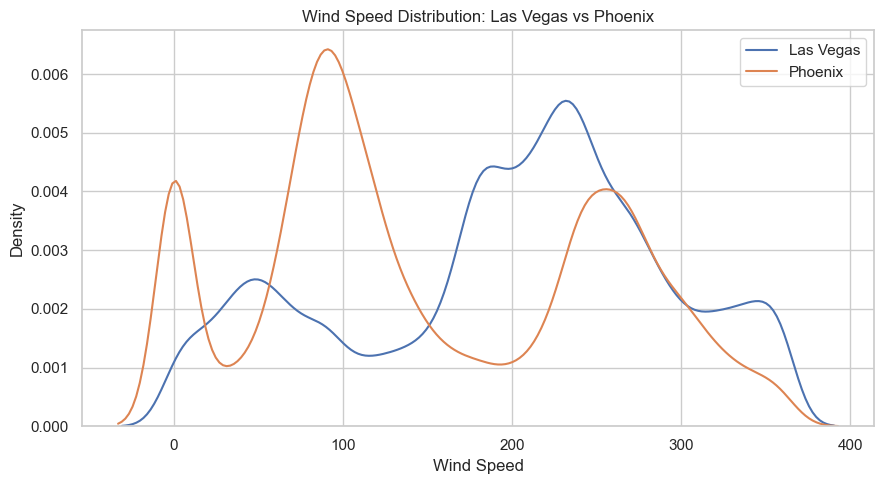

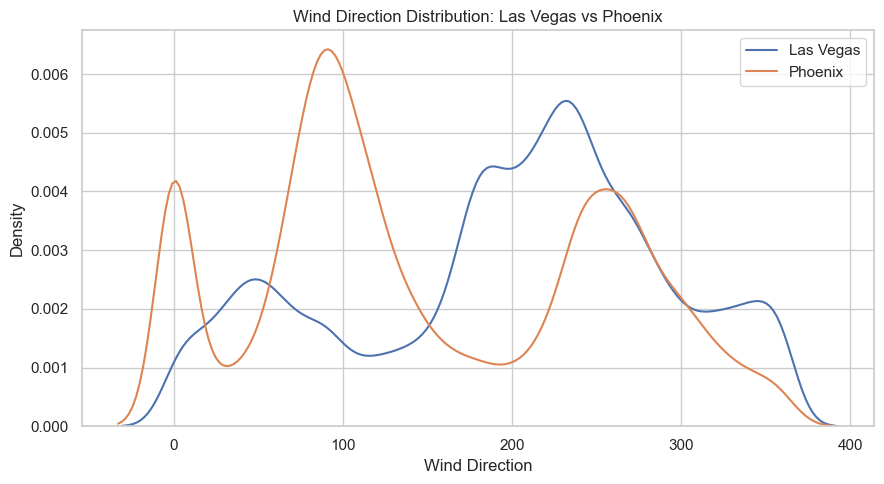

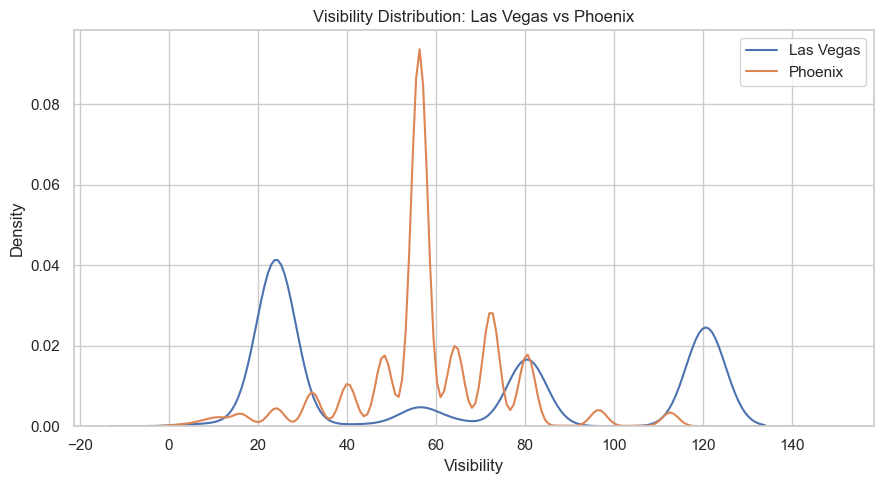

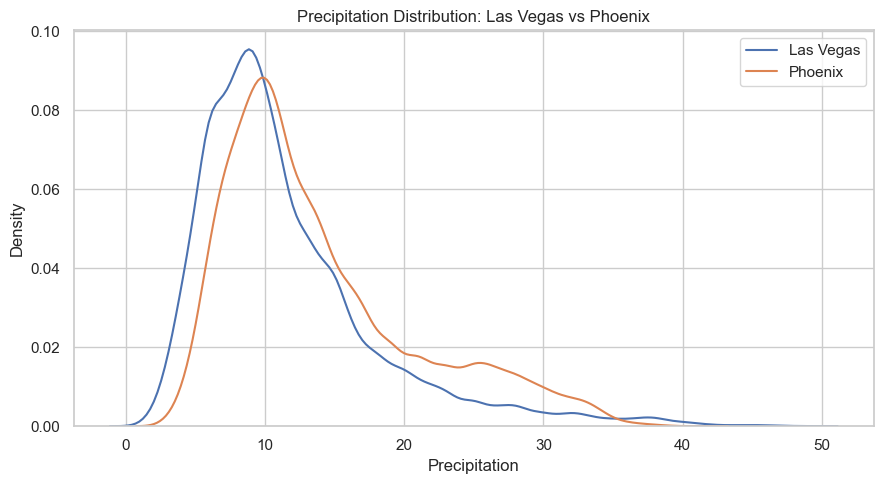

In [11]:
for feature in common_features:
    fig, ax = plt.subplots(figsize=(9, 5))
    for city in ["Las Vegas", "Phoenix"]:
        vals = aligned[city][feature].dropna()
        sns.kdeplot(vals, ax=ax, label=city, fill=False)
    ax.set_title(f"{feature.replace('_',' ').title()} Distribution: Las Vegas vs Phoenix")
    ax.set_xlabel(feature.replace("_", " ").title())
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{feature}_distribution.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 12. Monthly profile plots

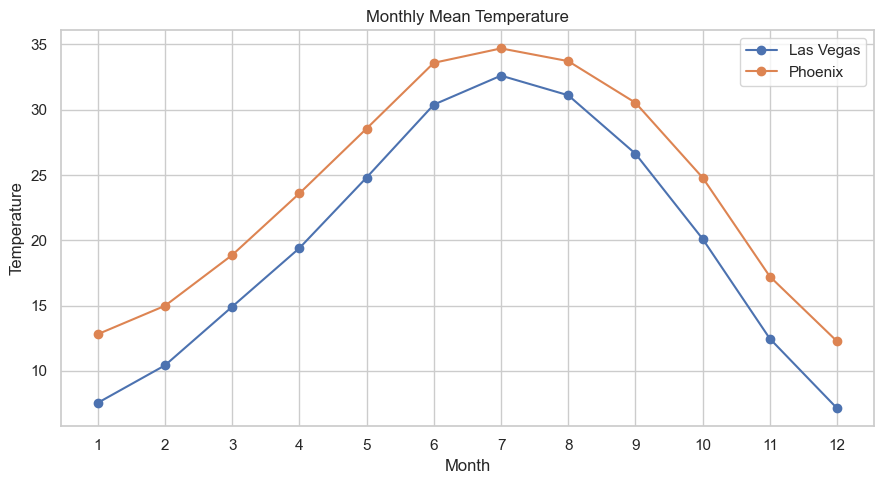

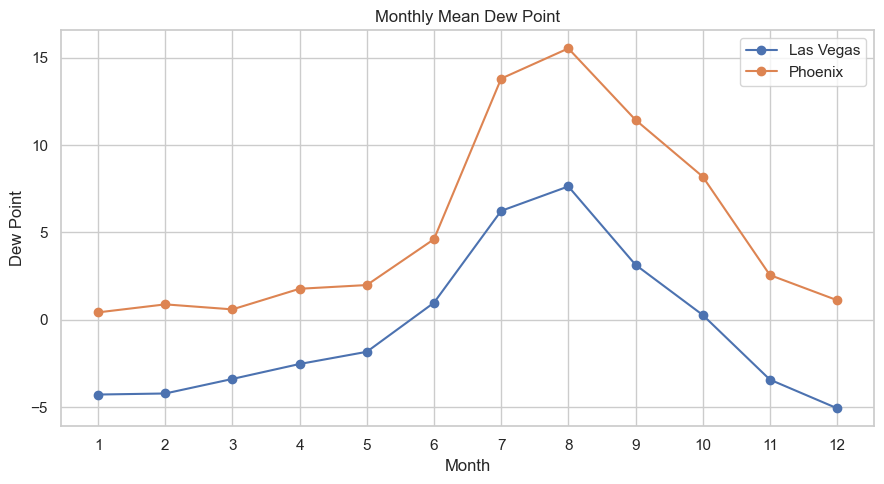

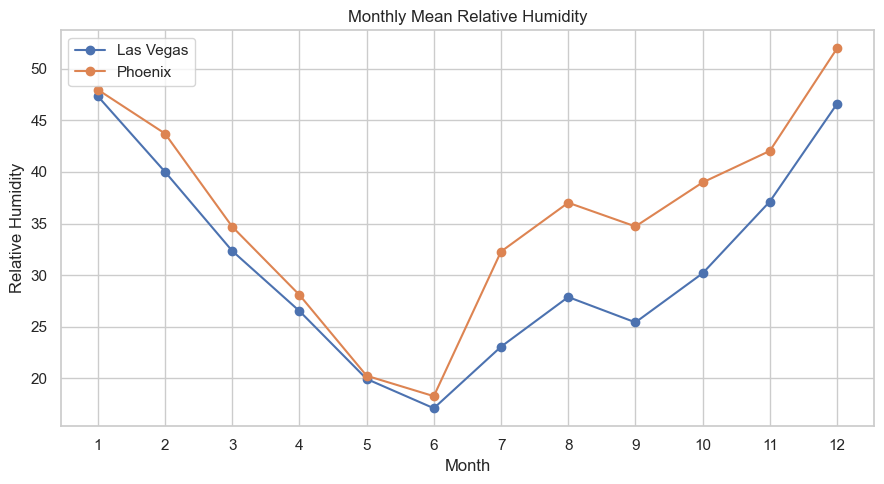

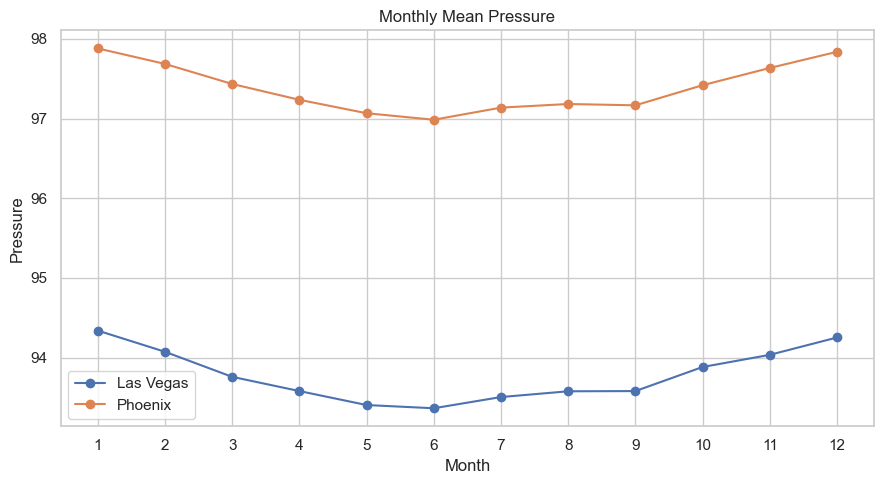

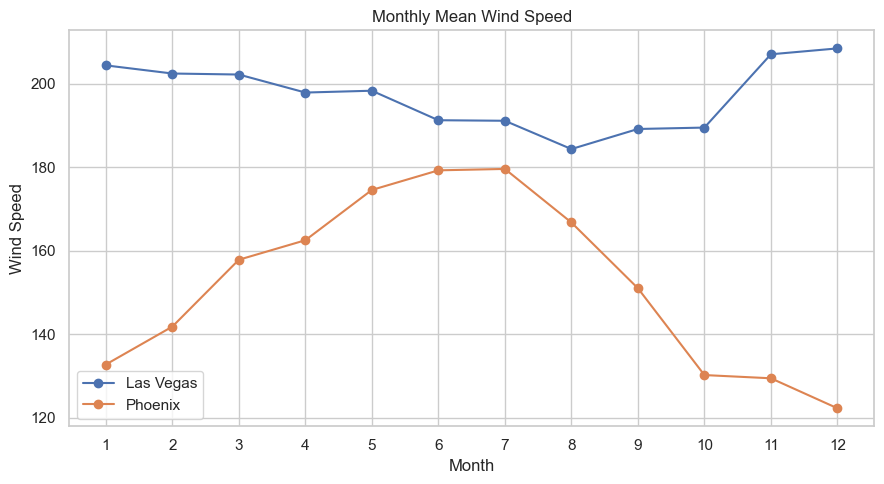

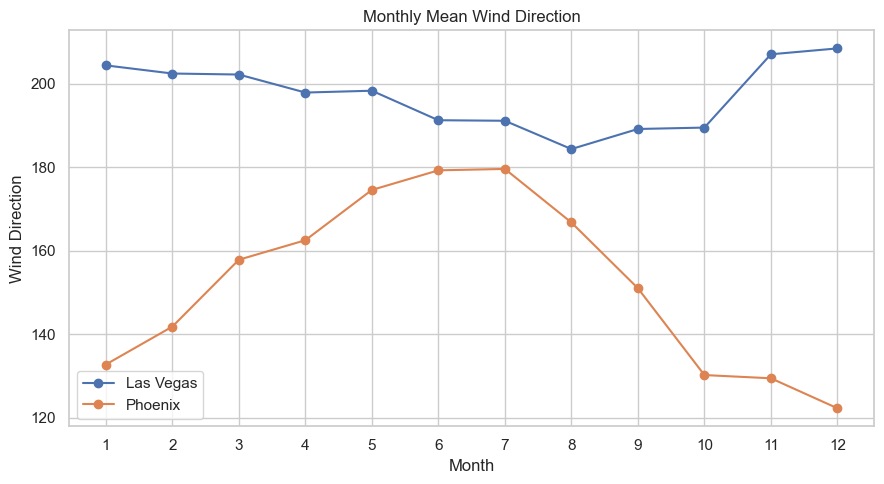

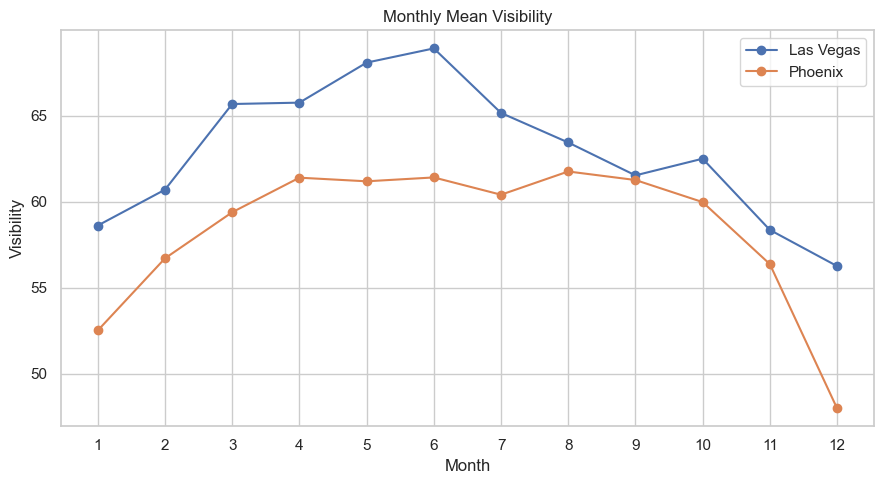

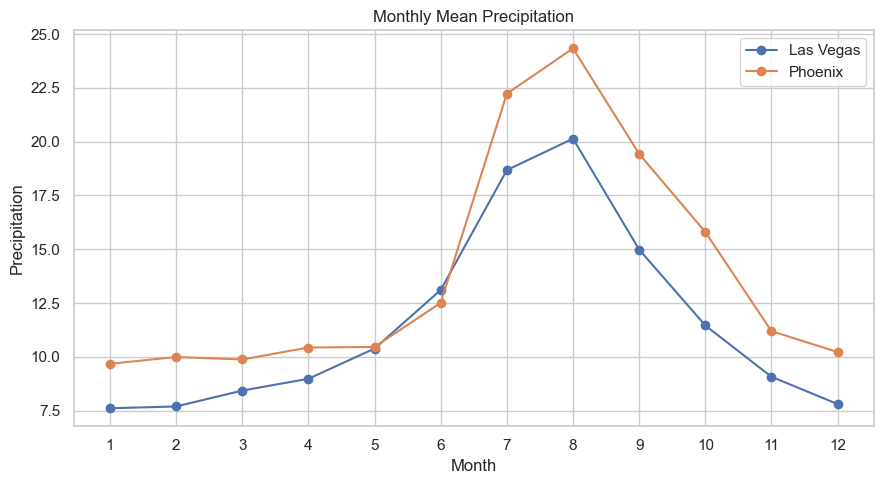

In [12]:
for feature in common_features:
    fig, ax = plt.subplots(figsize=(9, 5))
    for city in ["Las Vegas", "Phoenix"]:
        subset = monthly_means[monthly_means["city"] == city]
        ax.plot(subset["month"], subset[feature], marker="o", label=city)
    ax.set_xticks(range(1, 13))
    ax.set_title(f"Monthly Mean {feature.replace('_',' ').title()}")
    ax.set_xlabel("Month")
    ax.set_ylabel(feature.replace("_", " ").title())
    ax.legend()
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{feature}_monthly_profile.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## 13. Weather correlation structures

A climate pair is more useful for model transfer if not only the marginal distributions but also the relationships between weather variables are reasonably similar.

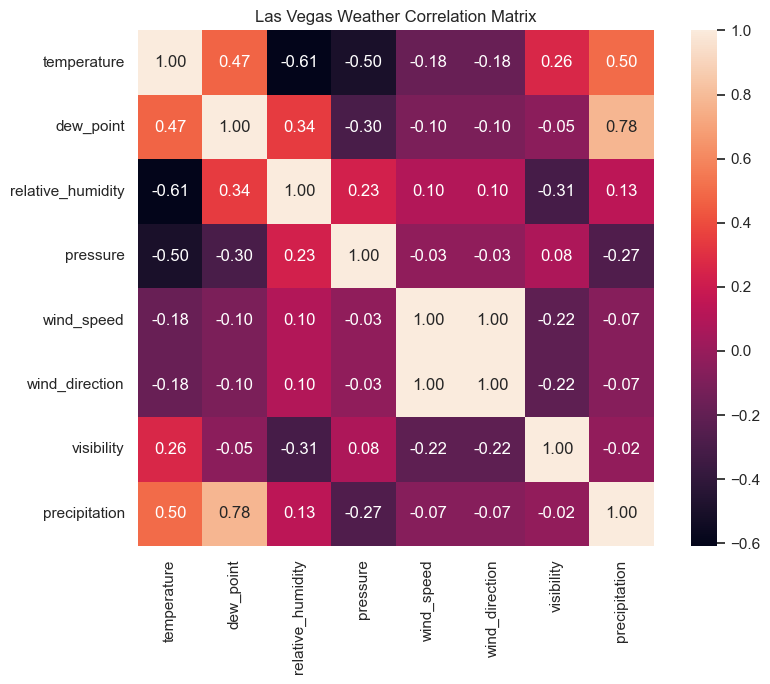

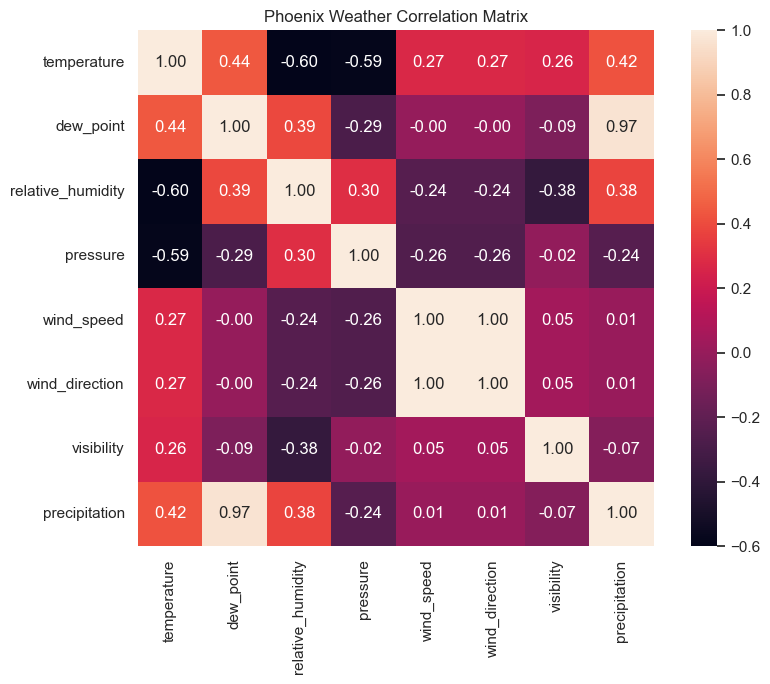

Correlation-structure similarity: 85.79/100


In [13]:
corrs = {}
for city, df in aligned.items():
    corrs[city] = df[common_features].corr(method="pearson")
    corrs[city].to_csv(TABLE_DIR / f"{city.lower().replace(' ','_')}_weather_pearson_correlation.csv")

    fig, ax = plt.subplots(figsize=(9, 7))
    sns.heatmap(corrs[city], annot=True, fmt=".2f", ax=ax, square=True)
    ax.set_title(f"{city} Weather Correlation Matrix")
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{city.lower().replace(' ','_')}_correlation_heatmap.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

corr_diff = corrs["Las Vegas"] - corrs["Phoenix"]
corr_similarity = 1 - np.mean(np.abs(corr_diff.values[np.triu_indices_from(corr_diff, k=1)]))
corr_similarity_score = float(np.clip(corr_similarity, 0, 1) * 100)

print(f"Correlation-structure similarity: {corr_similarity_score:.2f}/100")
corr_diff.to_csv(TABLE_DIR / "correlation_matrix_difference.csv")


## 14. Multivariate climate distance

To avoid one variable dominating because of its measurement scale, every weather variable is standardized using the pooled Las Vegas/Phoenix observations.

For each city, the mean standardized climate vector is calculated. The Euclidean distance between those vectors is the multivariate climate distance.

A smaller distance means greater similarity.

In [14]:
# Pooled standardization
pooled = pd.concat([
    aligned["Las Vegas"][common_features].assign(city="Las Vegas"),
    aligned["Phoenix"][common_features].assign(city="Phoenix")
], ignore_index=True)

valid = pooled[common_features].dropna()
scaler = StandardScaler()
scaler.fit(valid[common_features])

city_vectors = {}
for city in ["Las Vegas", "Phoenix"]:
    x = aligned[city][common_features].dropna()
    z = scaler.transform(x)
    city_vectors[city] = np.nanmean(z, axis=0)

vector_df = pd.DataFrame(city_vectors, index=common_features)
display(vector_df)

multivariate_distance = float(np.linalg.norm(vector_df["Las Vegas"] - vector_df["Phoenix"]))

print(f"Multivariate standardized climate distance = {multivariate_distance:.4f}")

vector_df.to_csv(TABLE_DIR / "standardized_climate_vectors.csv")


,Las Vegas,Phoenix
temperature,-0.1925,0.1925
dew_point,-0.3634,0.3634
relative_humidity,-0.1177,0.1177
pressure,-0.9617,0.9617
wind_speed,0.2221,-0.2221
wind_direction,0.2221,-0.2221
visibility,0.0721,-0.0721
precipitation,-0.1693,0.1693


Multivariate standardized climate distance = 2.2274


## 15. PCA climate-space visualization

PCA is used only as a visualization aid. It is not the primary similarity metric.

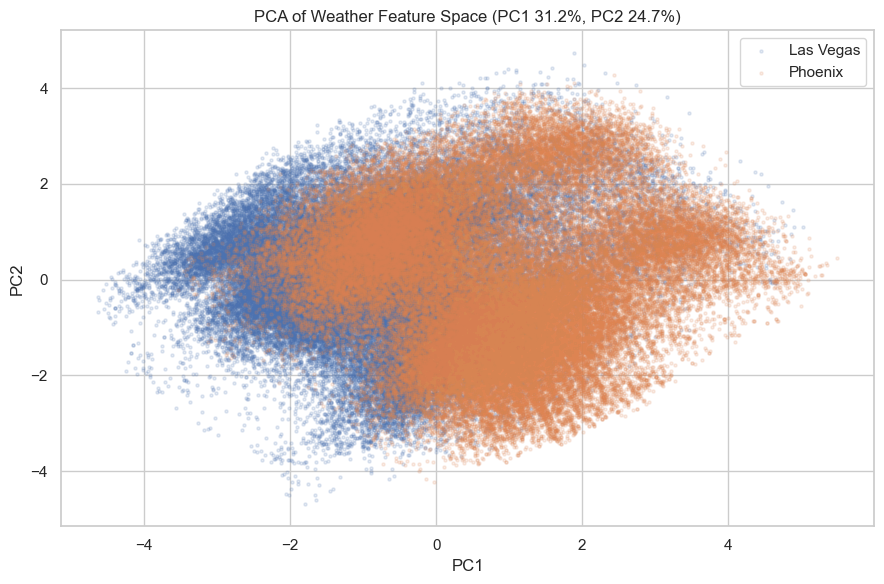

In [15]:
pca_input = pooled.dropna(subset=common_features).copy()
Xz = scaler.transform(pca_input[common_features])

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(Xz)

pca_df = pd.DataFrame(coords, columns=["PC1", "PC2"])
pca_df["city"] = pca_input["city"].values

fig, ax = plt.subplots(figsize=(9, 6))
for city in ["Las Vegas", "Phoenix"]:
    s = pca_df[pca_df["city"] == city]
    ax.scatter(s["PC1"], s["PC2"], s=5, alpha=0.15, label=city)

ax.set_title(
    f"PCA of Weather Feature Space "
    f"(PC1 {pca.explained_variance_ratio_[0]*100:.1f}%, "
    f"PC2 {pca.explained_variance_ratio_[1]*100:.1f}%)"
)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_DIR / "pca_climate_space.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

pca_df.to_csv(TABLE_DIR / "pca_coordinates.csv", index=False)


## 16. Overall climate similarity score

The final score combines three independent aspects:

1. **Distribution similarity**: average of variable-level similarity scores.
2. **Correlation-structure similarity**: similarity of pairwise Pearson correlations.
3. **Multivariate centroid similarity**: standardized Euclidean distance.

The score is intentionally transparent rather than pretending that there is one universally accepted "climate similarity" formula.

### Score components

- Distribution component: 60%
- Correlation component: 20%
- Multivariate component: 20%

For the multivariate component, the observed distance is transformed as:

\[
S_{multi}=100e^{-D}
\]

where \(D\) is the standardized Euclidean distance.

Interpretation thresholds used in this notebook:

- **80–100:** Highly similar
- **65–79.99:** Similar
- **50–64.99:** Moderately similar
- **Below 50:** Dissimilar

These thresholds are project-defined decision rules, not universal climatological standards.

In [16]:
distribution_score = float(variable_similarity["variable_similarity_score"].mean())
multivariate_score = float(100 * np.exp(-multivariate_distance))
overall_score = (
    0.60 * distribution_score
    + 0.20 * corr_similarity_score
    + 0.20 * multivariate_score
)

if overall_score >= 80:
    classification = "Highly similar"
elif overall_score >= 65:
    classification = "Similar"
elif overall_score >= 50:
    classification = "Moderately similar"
else:
    classification = "Dissimilar"

score_table = pd.DataFrame({
    "component": [
        "Distribution similarity",
        "Correlation structure similarity",
        "Multivariate climate similarity",
        "Overall climate similarity"
    ],
    "score_0_to_100": [
        distribution_score,
        corr_similarity_score,
        multivariate_score,
        overall_score
    ],
    "weight": [0.60, 0.20, 0.20, 1.00]
})

display(score_table)
print(f"\nFINAL CLIMATE SIMILARITY SCORE: {overall_score:.2f}/100")
print(f"CLASSIFICATION: {classification}")

score_table.to_csv(TABLE_DIR / "final_similarity_scores.csv", index=False)


,component,score_0_to_100,weight
0,Distribution similarity,59.6805,0.6000
1,Correlation structure similarity,85.7867,0.2000
2,Multivariate climate similarity,10.7813,0.2000
3,Overall climate similarity,55.1219,1.0000



FINAL CLIMATE SIMILARITY SCORE: 55.12/100
CLASSIFICATION: Moderately similar


## 17. Optional energy context

Energy is not used to calculate the climate similarity score. This section simply reports whether the supplied energy files appear structurally usable and whether the two cities have comparable coverage.

This distinction is important in a project defense: **weather similarity selects the city pair; energy is the target for the subsequent LSTM experiment.**

In [17]:
energy_rows = []
for city in data:
    df = data[city]["energy"].copy()
    tcol = detect_time_column(df)
    if tcol:
        ts = pd.to_datetime(df[tcol], errors="coerce")
    else:
        ts = pd.Series(pd.NaT, index=df.index)

    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
    energy_rows.append({
        "city": city,
        "rows": len(df),
        "timestamp_column": tcol,
        "start": ts.min(),
        "end": ts.max(),
        "numeric_columns": ", ".join(numeric_cols),
        "missing_pct": df.isna().mean().mean() * 100
    })

energy_audit = pd.DataFrame(energy_rows)
display(energy_audit)
energy_audit.to_csv(TABLE_DIR / "energy_audit.csv", index=False)


,city,rows,timestamp_column,start,end,numeric_columns,missing_pct
0,Las Vegas,70128,timestamp,2016-01-01,2023-12-31 23:00:00,hourly_load_mw,0.0000
1,Phoenix,70128,timestamp,2016-01-01,2023-12-31 23:00:00,hourly_load_mw,0.0000


## 18. Automatic findings

This cell converts the numerical analysis into statements that can be used in the report. The wording is generated from the actual results.

In [18]:
def fmt(x):
    return "N/A" if pd.isna(x) else f"{x:.3f}"

best = variable_similarity.sort_values("variable_similarity_score", ascending=False)
worst = variable_similarity.sort_values("variable_similarity_score", ascending=True)

findings = []

findings.append(
    f"The analysis used {len(common_features)} common meteorological variables: "
    + ", ".join(common_features) + "."
)

findings.append(
    f"The comparison used the common observed weather period from {common_start.date()} "
    f"to {common_end.date()}, after timestamp normalization and duplicate removal."
)

findings.append(
    f"The mean variable-level distribution similarity was {distribution_score:.2f}/100."
)

findings.append(
    f"The weather correlation-structure similarity was {corr_similarity_score:.2f}/100."
)

findings.append(
    f"The standardized multivariate climate distance was {multivariate_distance:.4f}, "
    f"corresponding to a multivariate similarity score of {multivariate_score:.2f}/100."
)

findings.append(
    f"The final weighted climate similarity score was {overall_score:.2f}/100, "
    f"classified as '{classification}' using the predefined project thresholds."
)

findings.append(
    f"The most similar weather variable by the combined variable score was "
    f"{best.iloc[0]['feature']} ({best.iloc[0]['variable_similarity_score']:.2f}/100)."
)

findings.append(
    f"The least similar weather variable by the combined variable score was "
    f"{worst.iloc[0]['feature']} ({worst.iloc[0]['variable_similarity_score']:.2f}/100)."
)

for i, text in enumerate(findings, 1):
    print(f"{i}. {text}")


1. The analysis used 8 common meteorological variables: temperature, dew_point, relative_humidity, pressure, wind_speed, wind_direction, visibility, precipitation.
2. The comparison used the common observed weather period from 2016-01-01 to 2023-12-31, after timestamp normalization and duplicate removal.
3. The mean variable-level distribution similarity was 59.68/100.
4. The weather correlation-structure similarity was 85.79/100.
5. The standardized multivariate climate distance was 2.2274, corresponding to a multivariate similarity score of 10.78/100.
6. The final weighted climate similarity score was 55.12/100, classified as 'Moderately similar' using the predefined project thresholds.
7. The most similar weather variable by the combined variable score was relative_humidity (82.08/100).
8. The least similar weather variable by the combined variable score was pressure (0.07/100).


## 19. Generate the final report

The report contains methodology, actual numerical results, interpretation, limitations, and a professor-ready conclusion. It is generated only after the analysis cells have run.

In [19]:
def df_to_md(df, index=False):
    return df.to_markdown(index=index)

report_md = f"""# Las Vegas vs Phoenix Climate Similarity Report

## Executive conclusion

Las Vegas and Phoenix were evaluated using a **data-driven meteorological similarity procedure** based on their observed 2016–2023 weather data. The city pair was not selected solely from general geographic or climatological assumptions.

The final climate similarity score was **{overall_score:.2f}/100**, giving the pair a classification of **{classification}** under the project's predefined scoring thresholds.

The purpose of this analysis is to establish whether the two cities represent sufficiently similar climatic regimes to serve as a controlled pair for evaluating cross-city LSTM generalization.

## 1. Data used

### Las Vegas
- Weather: `{FILES["Las Vegas"]["weather"]}`
- Energy: `{FILES["Las Vegas"]["energy"]}`

### Phoenix
- Weather: `{FILES["Phoenix"]["weather"]}`
- Energy: `{FILES["Phoenix"]["energy"]}`

The climate similarity score uses **weather only**. Energy is kept as the downstream prediction target and is not used to select the city pair.

## 2. Preprocessing

1. CSV schemas were inspected.
2. Timestamp columns were detected and converted to datetime.
3. Duplicate timestamps were removed after sorting.
4. Weather observations were restricted to the requested 2016–2023 period.
5. Only meteorological variables available in both cities were used.
6. The comparison was restricted to the common overlapping date window:
   **{common_start} to {common_end}**.
7. Variables were standardized where necessary before multivariate comparison.

## 3. Common meteorological variables

{", ".join(common_features)}

## 4. Statistical evidence

### Variable-level comparison

{df_to_md(variable_similarity[[
    "feature",
    "LV_mean",
    "Phoenix_mean",
    "standardized_mean_difference",
    "wasserstein_distance",
    "normalized_wasserstein",
    "KS_statistic",
    "KS_p_value",
    "variable_similarity_score"
]])}

### Overall score components

{df_to_md(score_table)}

## 5. Interpretation

The variable-level analysis examines both central tendency and distributional shape. Standardized mean difference controls for measurement scale, while Wasserstein distance and the KS statistic provide distribution-level comparisons.

The correlation analysis additionally evaluates whether relationships among meteorological variables are similar between the cities.

The standardized multivariate distance provides a single geometry-based comparison in the common weather feature space.

## 6. Main findings

"""

for i, f in enumerate(findings, 1):
    report_md += f"{i}. {f}\n"

report_md += f"""

## 7. Why this supports the LSTM city-pair experiment

The intended model experiment is not simply to predict energy independently in two arbitrary cities. It is to investigate whether meteorological patterns learned in one city can generalize to another city with a similar climatic regime.

Therefore, the workflow is:

**Weather data → climate similarity analysis → city-pair selection → LSTM training → cross-city evaluation**

This makes Las Vegas and Phoenix a data-supported test case for model transfer/generalization, provided that the final score and supporting plots show sufficient similarity.

## 8. Professor-ready explanation

> We did not select Las Vegas and Phoenix arbitrarily. We first identified common meteorological variables in the two datasets and restricted the analysis to their overlapping 2016–2023 period. We compared their descriptive statistics, empirical weather distributions, and correlation structures. We then standardized the weather variables and calculated a multivariate climate distance. These independent measures were combined into a transparent similarity score. The resulting score was {overall_score:.2f}/100, classified as {classification} under our predefined thresholds. Therefore, the city pair was selected based on similarity in the observed meteorological feature space, and we then use the pair to test whether an LSTM trained on one city can generalize to another city under a comparable climate regime.

## 9. Important limitation

This analysis establishes **similarity under the selected meteorological variables and the available 2016–2023 data**. It does not claim that the two cities are identical climates in every climatological sense.

Similarity also does not guarantee identical electricity-demand behavior. Differences in population, building stock, utility infrastructure, socioeconomic activity, air-conditioning penetration, and local energy practices can cause different load responses even when weather is similar. Those factors are part of the reason cross-city model evaluation is meaningful.

## 10. Output files

All generated tables are stored in:

`{TABLE_DIR}`

All generated figures are stored in:

`{PLOT_DIR}`

This report is stored in:

`{REPORT_DIR}`
"""

md_path = REPORT_DIR / "las_vegas_phoenix_climate_similarity_report.md"
md_path.write_text(report_md, encoding="utf-8")

# HTML report using pandas' markdown conversion if available through Python markdown.
try:
    import markdown
    html = markdown.markdown(report_md, extensions=["tables", "fenced_code"])
except Exception:
    html = "<html><body><pre>" + report_md.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;") + "</pre></body></html>"

html_path = REPORT_DIR / "las_vegas_phoenix_climate_similarity_report.html"
html_path.write_text(
    "<html><head><meta charset='utf-8'><title>Las Vegas vs Phoenix Climate Similarity</title>"
    "<style>body{font-family:Arial,sans-serif;max-width:1100px;margin:40px auto;line-height:1.5}"
    "table{border-collapse:collapse;width:100%}th,td{border:1px solid #ccc;padding:6px}th{background:#eee}"
    "code{background:#f4f4f4;padding:2px 4px}</style></head><body>" + html + "</body></html>",
    encoding="utf-8"
)

print("Markdown report:", md_path)
print("HTML report:", html_path)


Markdown report: D:\Downloads\BTP\model_training\lstm_training_3\climate_similarity_analysis\report\las_vegas_phoenix_climate_similarity_report.md
HTML report: D:\Downloads\BTP\model_training\lstm_training_3\climate_similarity_analysis\report\las_vegas_phoenix_climate_similarity_report.html


## 20. Final viva summary

Use the output numbers from the cell below when explaining the method. Do not quote any result before the notebook has successfully loaded your actual datasets.

In [20]:
print("="*78)
print("PROFESSOR / VIVA SUMMARY")
print("="*78)
print(f"""
We selected Las Vegas and Phoenix using a data-driven climate similarity
procedure rather than an assumption based only on geography.

1. We compared common weather variables from the 2016–2023 datasets.
2. We checked data quality, timestamps, duplicates, missingness and coverage.
3. We compared the distributions using standardized mean difference,
   Wasserstein distance and the KS statistic.
4. We compared the weather correlation structures.
5. We standardized all common weather variables and calculated a
   multivariate climate distance.
6. These components produced an overall climate similarity score of
   {overall_score:.2f}/100.
7. Under our predefined thresholds, the pair is classified as:
   {classification.upper()}.

The reason this matters for our LSTM is that we want to test cross-city
generalization under a comparable climatic regime. Weather similarity is
therefore used to justify the city pair, while energy consumption remains
the downstream prediction target and is not used to select the pair.
""")
print("="*78)


PROFESSOR / VIVA SUMMARY

We selected Las Vegas and Phoenix using a data-driven climate similarity
procedure rather than an assumption based only on geography.

1. We compared common weather variables from the 2016–2023 datasets.
2. We checked data quality, timestamps, duplicates, missingness and coverage.
3. We compared the distributions using standardized mean difference,
   Wasserstein distance and the KS statistic.
4. We compared the weather correlation structures.
5. We standardized all common weather variables and calculated a
   multivariate climate distance.
6. These components produced an overall climate similarity score of
   55.12/100.
7. Under our predefined thresholds, the pair is classified as:
   MODERATELY SIMILAR.

The reason this matters for our LSTM is that we want to test cross-city
generalization under a comparable climatic regime. Weather similarity is
therefore used to justify the city pair, while energy consumption remains
the downstream prediction target and is